##Análise Exploratória de Dados (EDA) — Enchentes de Porto Alegre
Este notebook apresenta uma Análise Exploratória de Dados (EDA) desenvolvida a partir de informações geográficas disponibilizadas pela Universidade Federal do Rio Grande do Sul (UFRGS) e de dados do Instituto Nacional de Ciência e Tecnologia em Sistemas Inteligentes para Monitoramento e Análise de Informações (INCT SiMAI).

A análise contempla a validação e o tratamento de camadas geográficas, o cálculo de áreas de interseção com os bairros de Porto Alegre e a comparação entre a água observada em 6 de maio de 2024 e a mancha associada ao nível de 5,3 metros. Além disso, são integrados indicadores do INCT referentes à quantidade de edificações e à população potencialmente afetadas nesse cenário.

Por meio de gráficos, mapas e medidas estatísticas, busca-se identificar padrões de cobertura territorial, diferenças entre as representações espaciais e relações entre a extensão das áreas mapeadas e os impactos estimados.

Os resultados têm como finalidade contribuir para o desenvolvimento de visualizações mais claras e informativas no projeto, permitindo relacionar dados territoriais e indicadores de impacto. Ressalta-se que as análises possuem caráter exploratório e devem considerar as diferenças metodológicas e as limitações das bases utilizadas.

In [2]:
pip install geopandas pandas pyogrio

   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
    --------------------------------------- 0.3/10.9 MB ? eta -:--:--
   - -------------------------------------- 0.5/10.9 MB 517.8 kB/s eta 0:00:21
   - -------------------------------------- 0.5/10.9 MB 517.8 kB/s eta 0:00:21
   - -------------------------------------- 0.5/10.9 MB 517.8 kB/s eta 0:00:21
   - -------------------------------------- 0.5/10.9 MB 517.8 kB/s eta 0:00:21
   - -------------------------------------- 0.5/10.9 MB 517.8 kB/s eta 0:00:21
   - -------------------------------------- 0.5/10.9 MB 517.8 kB/s eta 0:00:21
   -- ------------------------------------- 0.8/10.9 MB 297.6 kB/s eta 0:00:34
   -- ---------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import geopandas as gpd
import pandas as pd

In [4]:
arquivo = "cheias_rhguaiba_2024_db_v12.gpkg"

# Listar as camadas disponíveis
camadas = gpd.list_layers(arquivo)

print("Quantidade de camadas:", len(camadas))
display(camadas)

Quantidade de camadas: 51


,name,geometry_type
0,poa_admin_bairros,MultiPolygon Z
1,poa_inundacao_1941_475cm,MultiPolygon
2,poa_inundacao_1967_313cm,MultiPolygon
3,poa_inundacao_2015_294cm,MultiPolygon
4,poa_inundacao_2023_nov_346cm,Polygon
5,poa_inundacao_2023_set_318cm,MultiPolygon
6,poa_inundacao_2024_530cm,MultiPolygon
7,poa_inundacao_simulada_500cm,MultiPolygon
8,poa_inundacao_simulada_550cm,MultiPolygon
9,poa_inundacao_simulada_600cm,Polygon


In [5]:

# Selecionar a camada de inundação observada
nome_camada = "rhguaiba_sentinel2_agua_obs_06052024_validada"

# Ler a camada
gdf = gpd.read_file(arquivo, layer=nome_camada)

# Informações gerais
print("Quantidade de registros:", len(gdf))
print("Sistema de coordenadas:", gdf.crs)
print("Colunas disponíveis:", gdf.columns.tolist())

# Mostrar os primeiros registros
display(gdf.head())


Quantidade de registros: 4719
Sistema de coordenadas: EPSG:4326
Colunas disponíveis: ['CD_MUN', 'NM_MUN', 'SIGLA_UF', 'bacia', 'MUN_KM2', 'area_km2', 'geometry']


,CD_MUN,NM_MUN,SIGLA_UF,bacia,MUN_KM2,area_km2,geometry
0,4300109,Agudo,RS,Alto Jacui,534.624,6.492469,"POLYGON ((-51.69957 -29.9393, -51.70049 -29.94..."
1,4300109,Agudo,RS,Alto Jacui,534.624,1.084690,"POLYGON ((-51.70049 -29.94313, -51.69957 -29.9..."
2,4300109,Agudo,RS,Alto Jacui,534.624,1.862223,"POLYGON ((-51.70259 -29.95195, -51.70373 -29.9..."
3,4300109,Agudo,RS,Alto Jacui,534.624,5.444799,"POLYGON ((-51.70373 -29.95675, -51.70259 -29.9..."
4,4300109,Agudo,RS,Alto Jacui,534.624,0.000009,"POLYGON ((-51.70391 -29.95746, -51.70388 -29.9..."


In [6]:

print("Valores ausentes por coluna:")
print(gdf.isnull().sum())

print("\nGeometrias vazias:")
print(gdf.geometry.is_empty.sum())

print("\nGeometrias inválidas:")
print((~gdf.geometry.is_valid).sum())

print("\nTipos de dados:")
print(gdf.dtypes)




Valores ausentes por coluna:
CD_MUN      0
NM_MUN      0
SIGLA_UF    0
bacia       0
MUN_KM2     0
area_km2    0
geometry    0
dtype: int64

Geometrias vazias:
0

Geometrias inválidas:
0

Tipos de dados:
CD_MUN           str
NM_MUN           str
SIGLA_UF         str
bacia            str
MUN_KM2      float64
area_km2     float64
geometry    geometry
dtype: object


In [7]:

# Verificar duplicatas e inconsistências nas áreas

print("Registros duplicados:")
print(gdf.duplicated(
    subset=["CD_MUN", "area_km2", "geometry"]
).sum())

print("\nÁreas negativas ou iguais a zero:")
print((gdf["area_km2"] <= 0).sum())

print("\nMunicípios diferentes:")
print(gdf["NM_MUN"].nunique())

print("\nEstatísticas das áreas:")
display(gdf["area_km2"].describe())


Registros duplicados:
0

Áreas negativas ou iguais a zero:
0

Municípios diferentes:
1

Estatísticas das áreas:


count    4.719000e+03
mean     6.939622e-01
std      6.995182e+00
min      8.573971e-08
25%      8.124138e-05
50%      3.564551e-04
75%      3.663280e-03
max      2.356128e+02
Name: area_km2, dtype: float64

In [8]:

# Investigar a identificação dos municípios

print("Municípios encontrados:")
print(gdf["NM_MUN"].value_counts(dropna=False))

print("\nCódigos de municípios:")
print(gdf["CD_MUN"].value_counts(dropna=False).head(20))

print("\nBacias hidrográficas:")
print(gdf["bacia"].value_counts(dropna=False))

print("\nExemplos de registros:")
display(
    gdf[["CD_MUN", "NM_MUN", "bacia", "area_km2"]].sample(
        min(10, len(gdf)),
        random_state=42
    )
)


Municípios encontrados:
NM_MUN
Agudo    4719
Name: count, dtype: int64

Códigos de municípios:
CD_MUN
4300109    4719
Name: count, dtype: int64

Bacias hidrográficas:
bacia
Alto Jacui    4719
Name: count, dtype: int64

Exemplos de registros:


,CD_MUN,NM_MUN,bacia,area_km2
1210,4300109,Agudo,Alto Jacui,0.166691
2029,4300109,Agudo,Alto Jacui,0.000061
3979,4300109,Agudo,Alto Jacui,0.002248
3729,4300109,Agudo,Alto Jacui,0.000026
3704,4300109,Agudo,Alto Jacui,0.000003
291,4300109,Agudo,Alto Jacui,0.000064
3611,4300109,Agudo,Alto Jacui,0.000087
2389,4300109,Agudo,Alto Jacui,0.000432
3480,4300109,Agudo,Alto Jacui,10.051514
960,4300109,Agudo,Alto Jacui,0.005786


In [10]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 3.7 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.5 MB 3.3 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.5 MB 3.3 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.5 MB 3.1 MB/s eta 0:00:03
   ------------- -------------------------- 3.1/9.5 MB 3.1 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.5 MB 3.1 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.5 MB 3.0 MB/s eta 0:00:02
   -------------------- ------------------- 5.0/9.5 MB 3.0 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 3.0 MB/s eta 0:00:02
   -------------------------- ------------- 6.3/9.5 MB 3.1 MB/s eta 0:00:02
   ----------------------------- ---------- 7.1/9.5 MB 3.1 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.5 MB 3.1 MB/s eta 0:00:01
   ----------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Limites geográficos (longitude e latitude):
[-54.046513  -30.463935  -50.963534  -29.4711112]


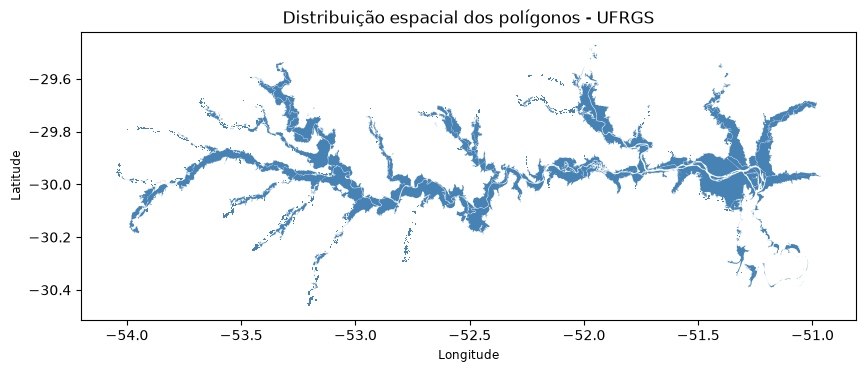

In [11]:

# Verificar a extensão geográfica da camada

print("Limites geográficos (longitude e latitude):")
print(gdf.total_bounds)

# Visualizar a distribuição espacial
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 7))

gdf.plot(ax=ax, color="steelblue", edgecolor="none")

ax.set_title("Distribuição espacial dos polígonos - UFRGS")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()


In [12]:

# Carregar os limites dos bairros de Porto Alegre
bairros_poa = gpd.read_file(
    arquivo,
    layer="poa_admin_bairros"
)

# Garantir o mesmo sistema de coordenadas
bairros_poa = bairros_poa.to_crs(gdf.crs)

# Unir os bairros em uma única geometria
limite_poa = bairros_poa.geometry.union_all()

# Verificar interseções
intersecoes = gdf.geometry.intersects(limite_poa)

print("Total de polígonos:", len(gdf))
print("Polígonos que intersectam Porto Alegre:",
      intersecoes.sum())

print("Polígonos sem interseção com Porto Alegre:",
      (~intersecoes).sum())


Total de polígonos: 4719
Polígonos que intersectam Porto Alegre: 34
Polígonos sem interseção com Porto Alegre: 4685


In [13]:

from pathlib import Path

# Criar uma cópia apenas com os polígonos
# que intersectam os bairros de Porto Alegre
gdf_poa = gdf.loc[intersecoes].copy()

# Recortar os polígonos aos limites dos bairros
gdf_poa = gpd.clip(gdf_poa, limite_poa)

# Remover atributos territoriais inconsistentes
gdf_poa = gdf_poa.drop(
    columns=["CD_MUN", "NM_MUN", "bacia"],
    errors="ignore"
)

# Calcular novamente as áreas após o recorte
# SIRGAS 2000 / UTM 22S
gdf_poa_metros = gdf_poa.to_crs(epsg=31982)
gdf_poa["area_km2"] = (
    gdf_poa_metros.geometry.area / 1_000_000
)

# Salvar os dados tratados
Path("dados/tratados").mkdir(parents=True, exist_ok=True)

gdf_poa.to_file(
    "dados/tratados/ufrgs_poa_limpo.gpkg",
    driver="GPKG"
)

print("Polígonos após o recorte:", len(gdf_poa))
print("Área somada dos polígonos (km²):",
      round(gdf_poa["area_km2"].sum(), 2))


Polígonos após o recorte: 34
Área somada dos polígonos (km²): 119.88


In [14]:
# Converter para sistema de coordenadas em metros
gdf_metros = gdf_poa.to_crs(epsg=31982)

# Unir as geometrias para evitar dupla contagem
geometria_unida = gdf_metros.geometry.union_all()

# Calcular a área única em km²
area_unica = geometria_unida.area / 1_000_000

# Comparar com a soma original
area_somada = gdf_metros.geometry.area.sum() / 1_000_000

print(f"Soma das áreas: {area_somada:.2f} km²")
print(f"Área da união: {area_unica:.2f} km²")
print(f"Sobreposição estimada: {area_somada - area_unica:.2f} km²")


Soma das áreas: 119.88 km²
Área da união: 119.88 km²
Sobreposição estimada: 0.00 km²


In [15]:
# Converter os bairros para o mesmo sistema projetado
bairros_metros = bairros_poa.to_crs(epsg=31982)

# Verificar os nomes das colunas dos bairros
print(bairros_metros.columns.tolist())

# Cruzar os bairros com a área observada
intersecao = gpd.overlay(
    bairros_metros,
    gdf_metros,
    how="intersection",
    keep_geom_type=False
)

# Calcular a área de cada interseção
intersecao["area_intersecao_km2"] = (
    intersecao.geometry.area / 1_000_000
)

print("Registros de interseção:", len(intersecao))
display(intersecao.head())

['nmbop', 'cdbop', 'nmrop', 'cdrop', 'nmrp', 'cdrp', 'cota_mean', 'geometry']
Registros de interseção: 64


,nmbop,cdbop,nmrop,cdrop,nmrp,cdrp,cota_mean,SIGLA_UF,MUN_KM2,area_km2,geometry,area_intersecao_km2
0,ANCHIETA,BOP19,HUMAITA-NAVEGANTES,OP01,HUMAITA - NAVEGANTES - ILHAS E NOROESTE,RP02,1.954820,RS,534.624,53.483621,"POLYGON Z ((484960.916 6685025.526 0, 484960.3...",5.255246
1,ARQUIPELAGO,BOP36,ILHAS,OP17,HUMAITA - NAVEGANTES - ILHAS E NOROESTE,RP02,1.162602,RS,534.624,1.892227,"POLYGON Z ((479280.904 6684071.266 0, 479288.0...",1.892227
2,ARQUIPELAGO,BOP36,ILHAS,OP17,HUMAITA - NAVEGANTES - ILHAS E NOROESTE,RP02,1.162602,RS,534.624,0.217528,"POLYGON Z ((471983.628 6674237.494 0, 471988.0...",0.217528
3,ARQUIPELAGO,BOP36,ILHAS,OP17,HUMAITA - NAVEGANTES - ILHAS E NOROESTE,RP02,1.162602,RS,534.624,0.012473,"POLYGON Z ((471726.138 6674841.145 0, 471733.3...",0.012473
4,ARQUIPELAGO,BOP36,ILHAS,OP17,HUMAITA - NAVEGANTES - ILHAS E NOROESTE,RP02,1.162602,RS,534.624,0.002257,"POLYGON Z ((473863.92 6674855.284 0, 473864.70...",0.002257


In [16]:

# Agrupar a área de interseção por bairro

area_por_bairro = (
    intersecao.groupby("nmbop", as_index=False)
    ["area_intersecao_km2"]
    .sum()
    .sort_values("area_intersecao_km2", ascending=False)
)

# Renomear as colunas
area_por_bairro.columns = [
    "bairro",
    "area_agua_km2"
]

print("Quantidade de bairros identificados:",
      len(area_por_bairro))

print("\n10 bairros com maiores áreas:")
display(area_por_bairro.head(10))


Quantidade de bairros identificados: 32

10 bairros com maiores áreas:


,bairro,area_agua_km2
1,ARQUIPELAGO,42.917473
27,SARANDI,21.061608
17,LAMI,11.313467
3,BELEM NOVO,7.412129
0,ANCHIETA,5.255246
26,SAO JOAO,4.880609
12,HUMAITA,4.231081
21,PONTA GROSSA,2.902512
22,PRAIA DE BELAS,2.536232
19,NAVEGANTES,2.210993


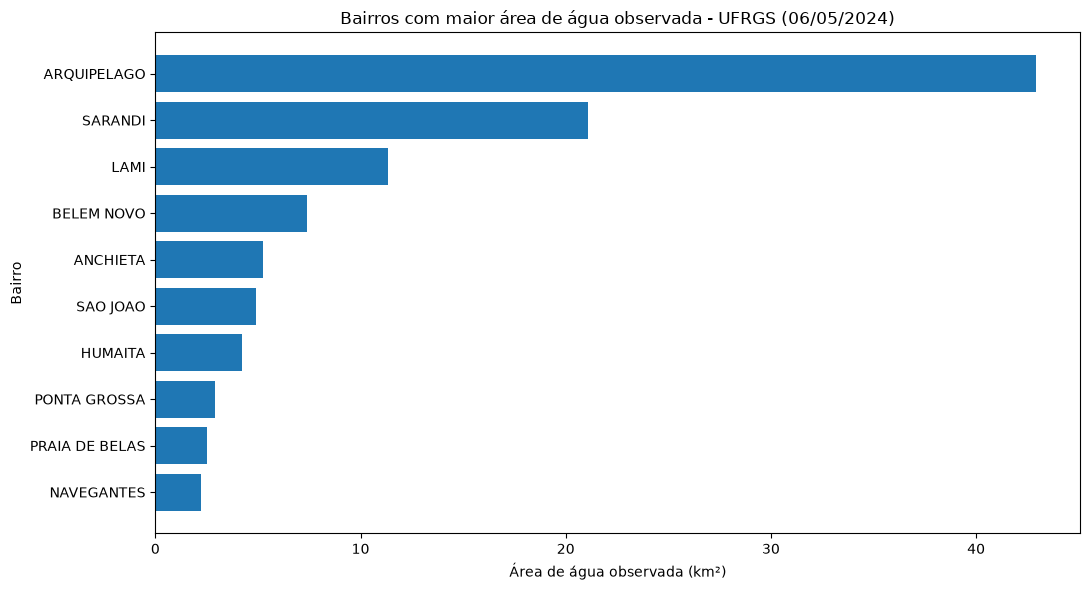

In [17]:
# Selecionar os 10 bairros com maiores áreas
top10 = area_por_bairro.head(10).sort_values(
    "area_agua_km2"
)

# Criar o gráfico
plt.figure(figsize=(11, 6))

plt.barh(
    top10["bairro"],
    top10["area_agua_km2"]
)

plt.xlabel("Área de água observada (km²)")
plt.ylabel("Bairro")
plt.title(
    "Bairros com maior área de água observada - UFRGS (06/05/2024)"
)

plt.tight_layout()
plt.show()


In [18]:
# Comparar a soma por bairro com a área da união

soma_bairros = area_por_bairro["area_agua_km2"].sum()

print(f"Soma das áreas por bairro: {soma_bairros:.2f} km²")
print(f"Área da união original: {area_unica:.2f} km²")
print(f"Diferença: {soma_bairros - area_unica:.2f} km²")


Soma das áreas por bairro: 119.88 km²
Área da união original: 119.88 km²
Diferença: 0.00 km²


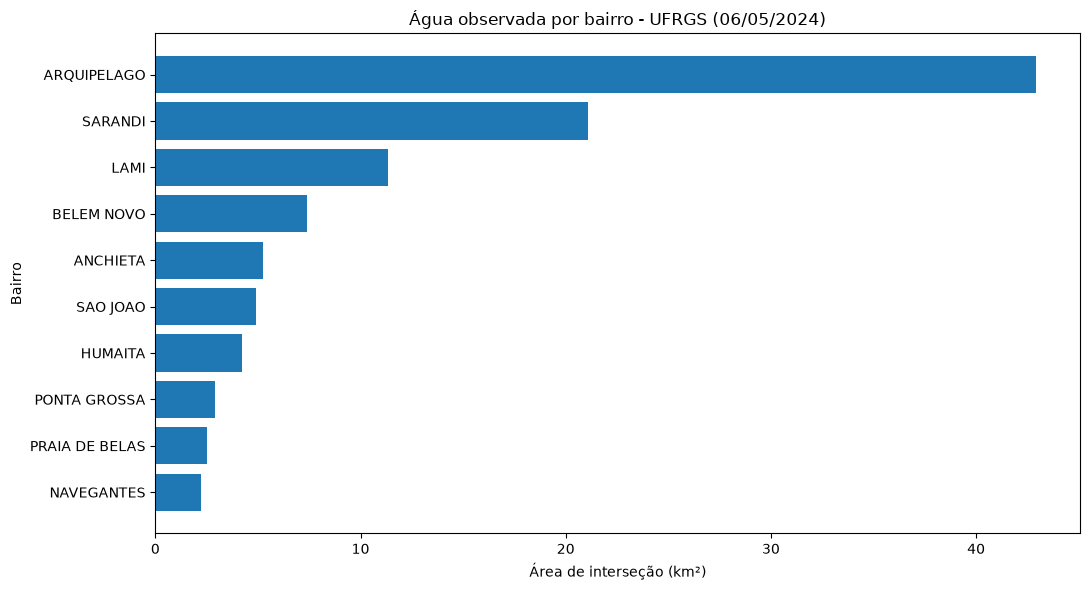

Tabela e gráfico salvos com sucesso!


In [19]:

from pathlib import Path

# Criar pastas para os resultados
Path("graficos").mkdir(exist_ok=True)
Path("dados/tratados").mkdir(parents=True, exist_ok=True)

# Exportar tabela por bairro
area_por_bairro.to_csv(
    "dados/tratados/ufrgs_area_por_bairro.csv",
    index=False,
    encoding="utf-8-sig"
)

# Criar e salvar o gráfico
top10 = area_por_bairro.head(10).sort_values("area_agua_km2")

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(top10["bairro"], top10["area_agua_km2"])

ax.set_title("Água observada por bairro - UFRGS (06/05/2024)")
ax.set_xlabel("Área de interseção (km²)")
ax.set_ylabel("Bairro")

plt.tight_layout()

fig.savefig(
    "graficos/ufrgs_area_por_bairro.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Tabela e gráfico salvos com sucesso!")


In [20]:

# Comparar a soma por bairro com a área da união

soma_bairros = area_por_bairro["area_agua_km2"].sum()

print(f"Soma das áreas por bairro: {soma_bairros:.2f} km²")
print(f"Área da união original: {area_unica:.2f} km²")
print(f"Diferença: {soma_bairros - area_unica:.2f} km²")


Soma das áreas por bairro: 119.88 km²
Área da união original: 119.88 km²
Diferença: 0.00 km²


In [21]:

# Segunda camada: água observada em 08/05/2024

camada_08 = gpd.read_file(
    arquivo,
    layer="rhguaiba-sinosgravatai_sentinel2_agua_obs_08052024_validada"
)

print("Quantidade de registros:", len(camada_08))
print("Sistema de coordenadas:", camada_08.crs)
print("Colunas disponíveis:", camada_08.columns.tolist())

display(camada_08.head())


Quantidade de registros: 1
Sistema de coordenadas: EPSG:4326
Colunas disponíveis: ['geometry']


,geometry
0,"MULTIPOLYGON (((-50.93134 -29.98125, -50.92972..."


In [22]:

print("1. Valores ausentes:")
print(camada_08.isnull().sum())

print("\n2. Geometrias vazias:")
print(camada_08.geometry.is_empty.sum())

print("\n3. Geometrias inválidas:")
print((~camada_08.geometry.is_valid).sum())

print("\n4. Registros totalmente duplicados:")
print(camada_08.duplicated().sum())

if "area_km2" in camada_08.columns:
    print("\n5. Áreas negativas ou zeradas:")
    print((camada_08["area_km2"] <= 0).sum())

if "NM_MUN" in camada_08.columns:
    print("\n6. Municípios encontrados:")
    print(camada_08["NM_MUN"].value_counts().head(10))

if "bacia" in camada_08.columns:
    print("\n7. Bacias hidrográficas:")
    print(camada_08["bacia"].value_counts())

print("\n8. Limites geográficos:")
print(camada_08.total_bounds)


1. Valores ausentes:
geometry    0
dtype: int64

2. Geometrias vazias:
0

3. Geometrias inválidas:
0

4. Registros totalmente duplicados:
0

8. Limites geográficos:
[-51.01299471 -30.07599623 -50.51622946 -29.65541941]


In [23]:

# Garantir que os dados estejam no mesmo CRS
bairros_08 = bairros_poa.to_crs(camada_08.crs)

# Unir os limites dos bairros de Porto Alegre
limite_poa_08 = bairros_08.geometry.union_all()

# Recortar a água observada para Porto Alegre
agua_08_poa = gpd.clip(
    camada_08,
    limite_poa_08
)

print("Registros após o recorte:", len(agua_08_poa))

# Separar os polígonos individuais
agua_08_poa = agua_08_poa.explode(
    index_parts=False
).reset_index(drop=True)

print("Polígonos individuais:", len(agua_08_poa))

# Projetar para coordenadas métricas
agua_08_metros = agua_08_poa.to_crs(epsg=31982)

# Calcular a área em km²
agua_08_poa["area_km2"] = (
    agua_08_metros.geometry.area / 1_000_000
)

print(
    "Área total de água em Porto Alegre:",
    round(agua_08_poa["area_km2"].sum(), 2),
    "km²"
)


Registros após o recorte: 0
Polígonos individuais: 0
Área total de água em Porto Alegre: 0.0 km²


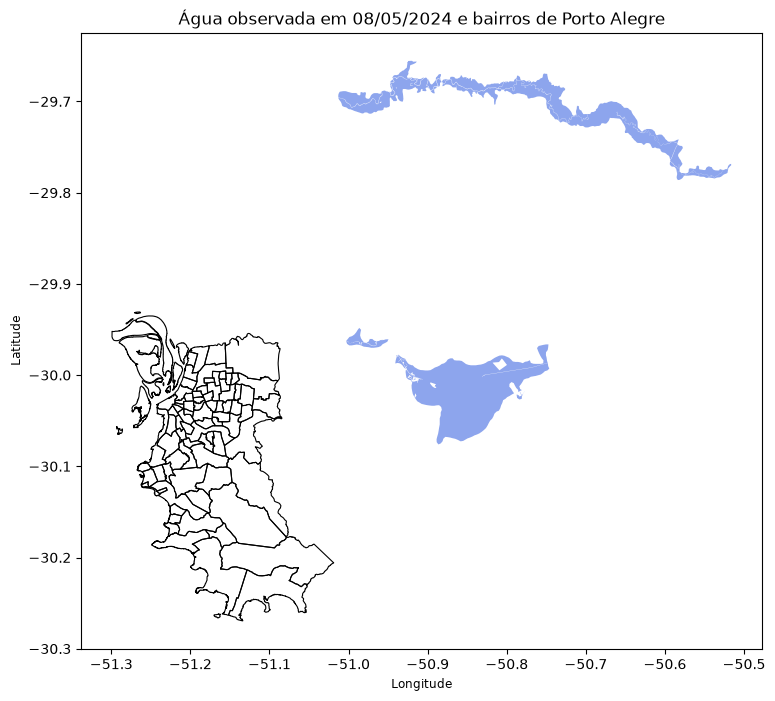

In [24]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 8))

# Limites dos bairros de Porto Alegre
bairros_08.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.8,
    label="Bairros de Porto Alegre"
)

# Água observada em 08/05/2024
camada_08.plot(
    ax=ax,
    color="royalblue",
    alpha=0.6
)

ax.set_title(
    "Água observada em 08/05/2024 e bairros de Porto Alegre"
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")

plt.show()


In [25]:

# Conferir os sistemas de coordenadas
print("CRS da água:", camada_08.crs)
print("CRS dos bairros:", bairros_08.crs)

# Conferir se há interseção espacial
print(
    "Existe interseção?",
    camada_08.geometry.intersects(
        limite_poa_08
    ).any()
)

# Distância mínima entre as geometrias (em metros)
agua_metros = camada_08.to_crs(epsg=31982)
bairros_metros_08 = bairros_08.to_crs(epsg=31982)

distancia = agua_metros.geometry.distance(
    bairros_metros_08.geometry.union_all()
).min()

print(
    "Distância mínima:",
    round(distancia, 2),
    "metros"
)


CRS da água: EPSG:4326
CRS dos bairros: EPSG:4326
Existe interseção? False
Distância mínima: 8117.18 metros


In [26]:

# Carregar a terceira camada
camada_530 = gpd.read_file(
    arquivo,
    layer="poa_inundacao_2024_530cm"
)

print("Quantidade de registros:", len(camada_530))
print("Sistema de coordenadas:", camada_530.crs)
print("Colunas disponíveis:", camada_530.columns.tolist())

print("\nTipos de geometria:")
print(camada_530.geom_type.value_counts())

print("\nValores ausentes:")
print(camada_530.isnull().sum())

print("\nGeometrias vazias:")
print(camada_530.geometry.is_empty.sum())

print("\nGeometrias inválidas:")
print((~camada_530.geometry.is_valid).sum())

display(camada_530.head())


Quantidade de registros: 478
Sistema de coordenadas: EPSG:31982
Colunas disponíveis: ['DN', 'geometry']

Tipos de geometria:
MultiPolygon    478
Name: count, dtype: int64

Valores ausentes:
DN          0
geometry    0
dtype: int64

Geometrias vazias:
0

Geometrias inválidas:
0


,DN,geometry
0,1,"MULTIPOLYGON (((473660.024 6688037.737, 473660..."
1,1,"MULTIPOLYGON (((477739.91 6685465.636, 477739...."
2,1,"MULTIPOLYGON (((473988.015 6687869.731, 473988..."
3,1,"MULTIPOLYGON (((475875.962 6686145.663, 475875..."
4,1,"MULTIPOLYGON (((485559.692 6684769.609, 485559..."


In [27]:

# Verificar valores existentes na coluna DN
print("Valores da coluna DN:")
print(camada_530["DN"].value_counts(dropna=False))

# Verificar geometrias repetidas
print("\nGeometrias duplicadas:")
print(camada_530.geometry.to_wkb().duplicated().sum())

# Calcular a área de cada registro
camada_530["area_km2"] = (
    camada_530.geometry.area / 1_000_000
)

print("\nResumo das áreas:")
print(camada_530["area_km2"].describe())

print("\nÁreas zeradas ou negativas:")
print((camada_530["area_km2"] <= 0).sum())

# Calcular área sem contar possíveis sobreposições
area_uniao_530 = (
    camada_530.geometry.union_all().area
    / 1_000_000
)

print("\nSoma das áreas:",
      round(camada_530["area_km2"].sum(), 2),
      "km²")

print("Área da união:",
      round(area_uniao_530, 2),
      "km²")


Valores da coluna DN:
DN
1    478
Name: count, dtype: int64

Geometrias duplicadas:
0

Resumo das áreas:
count    478.000000
mean       0.290035
std        3.209781
min        0.000016
25%        0.000016
50%        0.000032
75%        0.000112
max       51.403708
Name: area_km2, dtype: float64

Áreas zeradas ou negativas:
0

Soma das áreas: 138.64 km²
Área da união: 138.64 km²


In [28]:

# 1. Padronizar o CRS dos bairros
bairros_530 = bairros_poa.to_crs(epsg=31982)

# 2. Manter apenas os campos necessários
bairros_530 = bairros_530[
    ["nmbop", "geometry"]
].copy()

# 3. Unir os polígonos da mancha
mancha_unida_530 = camada_530.geometry.union_all()

# 4. Criar GeoDataFrame da mancha unificada
mancha_530_unida = gpd.GeoDataFrame(
    geometry=[mancha_unida_530],
    crs=camada_530.crs
)

# 5. Calcular a interseção com os bairros
intersecao_530 = gpd.overlay(
    bairros_530,
    mancha_530_unida,
    how="intersection",
    keep_geom_type=False
)

# 6. Calcular área de interseção em km²
intersecao_530["area_km2"] = (
    intersecao_530.geometry.area / 1_000_000
)

# 7. Agrupar os resultados por bairro
area_por_bairro_530 = (
    intersecao_530
    .groupby("nmbop", as_index=False)["area_km2"]
    .sum()
    .rename(columns={
        "nmbop": "bairro",
        "area_km2": "area_mancha_km2"
    })
    .sort_values(
        "area_mancha_km2",
        ascending=False
    )
)

print(
    "Bairros com interseção:",
    len(area_por_bairro_530)
)

print(
    "Área total dentro dos bairros:",
    round(
        area_por_bairro_530["area_mancha_km2"].sum(),
        2
    ),
    "km²"
)

display(area_por_bairro_530.head(10))


Bairros com interseção: 36
Área total dentro dos bairros: 137.66 km²


,bairro,area_mancha_km2
1,ARQUIPELAGO,42.064401
31,SARANDI,20.300517
3,BELEM NOVO,18.385895
18,LAMI,14.557246
22,PONTA GROSSA,5.873495
0,ANCHIETA,5.144052
30,SAO JOAO,4.825741
13,HUMAITA,4.047479
23,PRAIA DE BELAS,2.401550
12,HIPICA,2.342217


In [29]:

# Área somada por bairro
area_somada_530 = (
    area_por_bairro_530["area_mancha_km2"].sum()
)

# Área da união de todas as interseções
area_unica_530 = (
    intersecao_530.geometry.union_all().area
    / 1_000_000
)

print(
    "Soma das áreas por bairro:",
    round(area_somada_530, 4),
    "km²"
)

print(
    "Área da união das interseções:",
    round(area_unica_530, 4),
    "km²"
)

print(
    "Diferença:",
    round(area_somada_530 - area_unica_530, 4),
    "km²"
)


Soma das áreas por bairro: 137.6624 km²
Área da união das interseções: 137.6604 km²
Diferença: 0.0019 km²


In [30]:
# Quarta camada: limites dos bairros de Porto Alegre

print("Quantidade de bairros:", len(bairros_poa))
print("CRS:", bairros_poa.crs)

print("\nColunas:")
print(bairros_poa.columns.tolist())

print("\nValores ausentes:")
print(bairros_poa.isnull().sum())

print("\nGeometrias vazias:")
print(bairros_poa.geometry.is_empty.sum())

print("\nGeometrias inválidas:")
print((~bairros_poa.geometry.is_valid).sum())

print("\nNomes de bairros duplicados:")
print(bairros_poa["nmbop"].duplicated().sum())

print("\nTipos de geometria:")
print(bairros_poa.geom_type.value_counts())

display(bairros_poa.head())


Quantidade de bairros: 83
CRS: EPSG:4326

Colunas:
['nmbop', 'cdbop', 'nmrop', 'cdrop', 'nmrp', 'cdrp', 'cota_mean', 'geometry']

Valores ausentes:
nmbop        0
cdbop        0
nmrop        0
cdrop        0
nmrp         0
cdrp         0
cota_mean    0
geometry     0
dtype: int64

Geometrias vazias:
0

Geometrias inválidas:
0

Nomes de bairros duplicados:
0

Tipos de geometria:
MultiPolygon    83
Name: count, dtype: int64


,nmbop,cdbop,nmrop,cdrop,nmrp,cdrp,cota_mean,geometry
0,AGRONOMIA,BOP71,LOMBA DO PINHEIRO,OP04,LOMBA DO PINHEIRO - PARTENON,RP07,125.157306,"MULTIPOLYGON Z (((-51.11093 -30.03913 0, -51.1..."
1,ANCHIETA,BOP19,HUMAITA-NAVEGANTES,OP01,HUMAITA - NAVEGANTES - ILHAS E NOROESTE,RP02,1.954820,"MULTIPOLYGON Z (((-51.15587 -29.96491 0, -51.1..."
2,ARQUIPELAGO,BOP36,ILHAS,OP17,HUMAITA - NAVEGANTES - ILHAS E NOROESTE,RP02,1.162602,"MULTIPOLYGON Z (((-51.29067 -30.06265 0, -51.2..."
3,AUXILIADORA,BOP01,CENTRO,OP16,CENTRO,RP01,28.703022,"MULTIPOLYGON Z (((-51.18452 -30.02201 0, -51.1..."
4,AZENHA,BOP02,CENTRO,OP16,CENTRO,RP01,12.897710,"MULTIPOLYGON Z (((-51.2091 -30.05061 0, -51.20..."


In [31]:

# Projetar os bairros para coordenadas métricas
bairros_validacao = bairros_poa.to_crs(epsg=31982).copy()

# Calcular a área de cada bairro
bairros_validacao["area_bairro_km2"] = (
    bairros_validacao.geometry.area / 1_000_000
)

# Somar as áreas individuais
area_somada_bairros = (
    bairros_validacao["area_bairro_km2"].sum()
)

# Calcular a união dos bairros
uniao_bairros = bairros_validacao.geometry.union_all()

area_uniao_bairros = (
    uniao_bairros.area / 1_000_000
)

print("Soma das áreas dos bairros:",
      round(area_somada_bairros, 4), "km²")

print("Área da união dos bairros:",
      round(area_uniao_bairros, 4), "km²")

print("Diferença:",
      round(
          area_somada_bairros - area_uniao_bairros,
          4
      ), "km²")

print("\nBairros com área zerada:")
print(
    (bairros_validacao["area_bairro_km2"] <= 0).sum()
)

print("\nMaiores bairros:")
display(
    bairros_validacao[
        ["nmbop", "area_bairro_km2"]
    ].sort_values(
        "area_bairro_km2",
        ascending=False
    ).head(10)
)


Soma das áreas dos bairros: 470.6415 km²
Área da união dos bairros: 470.638 km²
Diferença: 0.0035 km²

Bairros com área zerada:
0

Maiores bairros:


,nmbop,area_bairro_km2
41,LAGEADO,44.800475
2,ARQUIPELAGO,44.222006
56,RESTINGA,38.864637
43,LOMBA DO PINHEIRO,28.741636
67,SARANDI,28.629635
6,BELEM NOVO,28.334515
42,LAMI,28.090760
0,AGRONOMIA,16.636730
76,VILA NOVA,11.001909
32,IPANEMA,10.176451


In [32]:

# Preparar as áreas totais dos bairros
areas_bairros = bairros_validacao[
    ["nmbop", "area_bairro_km2"]
].rename(columns={"nmbop": "bairro"})

# Juntar com as áreas da mancha de 5,3 m
percentual_530 = areas_bairros.merge(
    area_por_bairro_530,
    on="bairro",
    how="left"
)

# Bairros sem interseção recebem área zero
percentual_530["area_mancha_km2"] = (
    percentual_530["area_mancha_km2"].fillna(0)
)

# Calcular o percentual
percentual_530["percentual_cobertura"] = (
    percentual_530["area_mancha_km2"]
    / percentual_530["area_bairro_km2"]
) * 100

# Ordenar pelos maiores percentuais
percentual_530 = percentual_530.sort_values(
    "percentual_cobertura",
    ascending=False
)

print("Total de bairros:", len(percentual_530))

print("\nBairros com percentual acima de 100%:")
print(
    (percentual_530["percentual_cobertura"] > 100).sum()
)

display(percentual_530.head(10))


Total de bairros: 83

Bairros com percentual acima de 100%:
0


,bairro,area_bairro_km2,area_mancha_km2,percentual_cobertura
23,FARRAPOS,1.632852,1.601880,98.103187
49,NAVEGANTES,2.211867,2.165932,97.923265
1,ANCHIETA,5.256016,5.144052,97.869796
63,SAO GERALDO,1.884034,1.830123,97.138545
30,HUMAITA,4.231126,4.047479,95.659621
2,ARQUIPELAGO,44.222006,42.064401,95.120969
80,PRAIA DE BELAS,2.566979,2.401550,93.555503
68,SERRARIA,1.750375,1.524705,87.107357
64,SAO JOAO,5.940504,4.825741,81.234547
78,SANTA MARIA GORETTI,0.710535,0.570926,80.351521


In [33]:

from pathlib import Path

# Criar a pasta, caso ainda não exista
Path("dados/tratados").mkdir(
    parents=True,
    exist_ok=True
)

# Salvar os indicadores por bairro
percentual_530.to_csv(
    "dados/tratados/ufrgs_cobertura_530cm_por_bairro.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo CSV salvo com sucesso!")


Arquivo CSV salvo com sucesso!


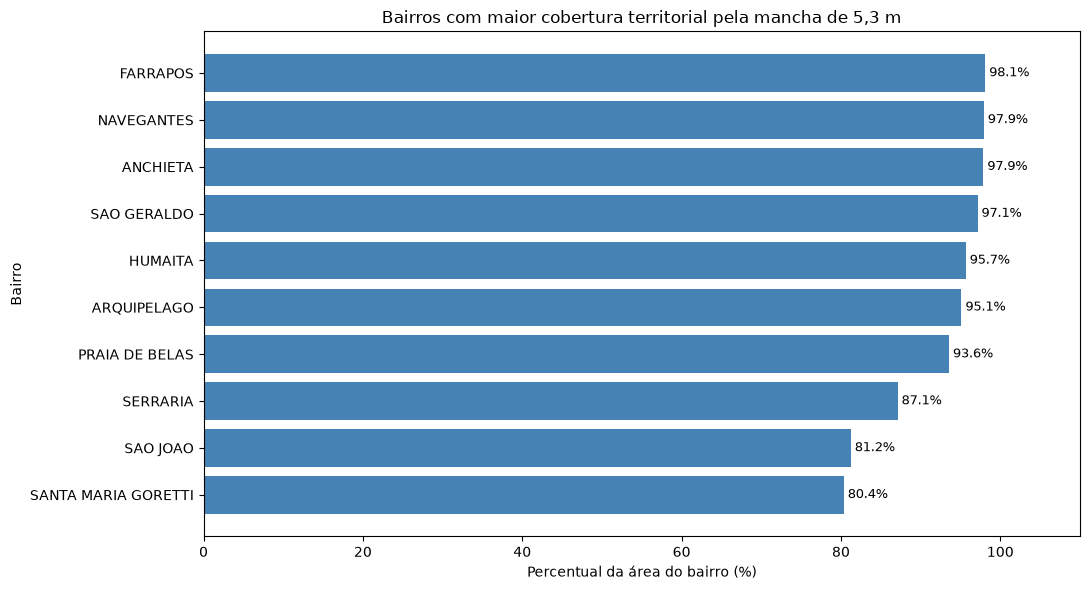

In [34]:

import matplotlib.pyplot as plt

# Selecionar os 10 bairros com maior percentual
top10_percentual = percentual_530.nlargest(
    10,
    "percentual_cobertura"
).sort_values("percentual_cobertura")

plt.figure(figsize=(11, 6))

barras = plt.barh(
    top10_percentual["bairro"],
    top10_percentual["percentual_cobertura"],
    color="steelblue"
)

# Exibir valores percentuais
for barra in barras:
    largura = barra.get_width()

    plt.text(
        largura + 0.5,
        barra.get_y() + barra.get_height() / 2,
        f"{largura:.1f}%",
        va="center",
        fontsize=9
    )

plt.title(
    "Bairros com maior cobertura territorial pela mancha de 5,3 m"
)

plt.xlabel("Percentual da área do bairro (%)")
plt.ylabel("Bairro")
plt.xlim(0, 110)

plt.tight_layout()
plt.show()


**Gráfico — Percentual de cobertura territorial da mancha de 5,3 m por bairro**

O gráfico apresenta os dez bairros de Porto Alegre com maiores percentuais de cobertura territorial pela mancha associada ao nível de 5,3 metros. Os resultados mostram que Farrapos (98,10%), Navegantes (97,92%) e Anchieta (97,87%) possuem os maiores percentuais de interseção.

A análise proporcional permite identificar bairros com elevada cobertura territorial, independentemente de sua extensão geográfica. Entretanto, esses percentuais não representam diretamente a proporção de edificações ou habitantes afetados, pois consideram exclusivamente a área geográfica dos bairros.

In [35]:
from pathlib import Path

Path("graficos").mkdir(exist_ok=True)

plt.tight_layout()
plt.savefig(
    "graficos/ufrgs_percentual_cobertura_530cm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

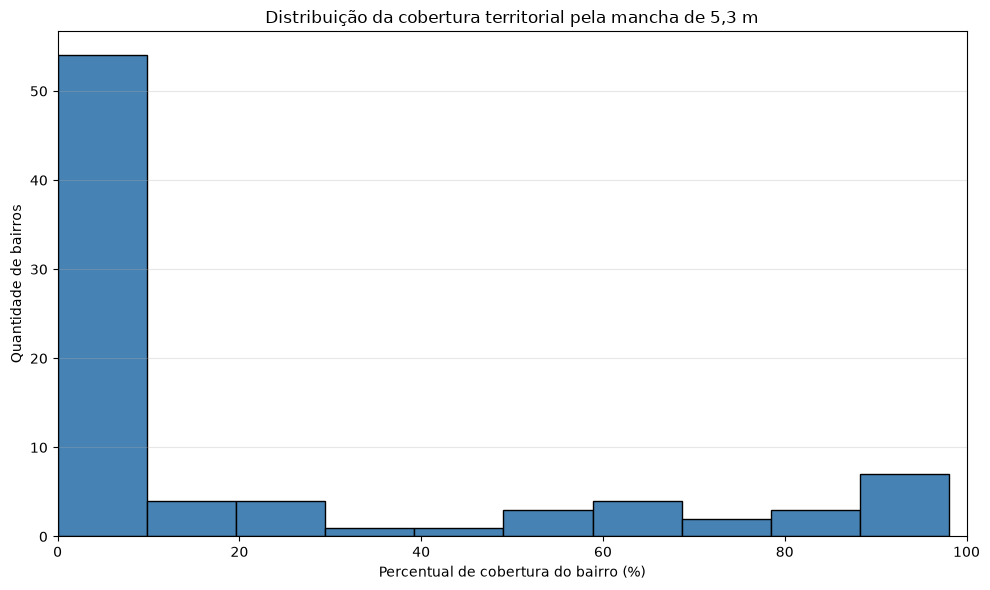

In [36]:

import matplotlib.pyplot as plt
from pathlib import Path

Path("graficos").mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

plt.hist(
    percentual_530["percentual_cobertura"],
    bins=10,
    edgecolor="black",
    color="steelblue"
)

plt.title(
    "Distribuição da cobertura territorial pela mancha de 5,3 m"
)

plt.xlabel("Percentual de cobertura do bairro (%)")
plt.ylabel("Quantidade de bairros")

plt.xlim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "graficos/ufrgs_distribuicao_cobertura_530cm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Gráfico — Distribuição da cobertura territorial pela mancha de 5,3 m

O histograma apresenta a distribuição dos percentuais de cobertura territorial da mancha de 5,3 metros entre os 83 bairros de Porto Alegre.

Observa-se uma concentração expressiva de bairros na faixa de 0% a 10% de cobertura, enquanto um grupo menor apresenta percentuais elevados, próximos de 100%. Os resultados indicam uma distribuição espacial desigual da mancha, com diferentes níveis de cobertura territorial entre os bairros.

Essa análise complementa o ranking dos bairros com maiores percentuais de cobertura e contribui para identificar padrões relevantes para a visualização dos dados no sistema. Ressalta-se que o percentual representa a área territorial intersectada pela mancha, não a proporção de moradores ou edificações afetadas.

In [37]:

cobertura = percentual_530["percentual_cobertura"]

print("Média:", round(cobertura.mean(), 2), "%")
print("Mediana:", round(cobertura.median(), 2), "%")

print("Bairros sem interseção:",
      (cobertura == 0).sum())

print("Bairros entre 0% e 10%:",
      ((cobertura > 0) & (cobertura <= 10)).sum())

print("Bairros acima de 50%:",
      (cobertura > 50).sum())

print("Bairros acima de 90%:",
      (cobertura > 90).sum())


Média: 20.75 %
Mediana: 0.0 %
Bairros sem interseção: 47
Bairros entre 0% e 10%: 7
Bairros acima de 50%: 19
Bairros acima de 90%: 7


### Gráfico — Distribuição da cobertura territorial pela mancha de 5,3 m

O histograma apresenta a distribuição dos percentuais de cobertura territorial da mancha de 5,3 metros entre os 83 bairros de Porto Alegre.

Os resultados demonstram uma distribuição desigual, com média de cobertura de 20,75% e mediana de 0% já que 47 dos 83 bairros apresentam cobertura igual a zero. Dos 83 bairros analisados, 47 (56,6%) não apresentaram interseção com a mancha, enquanto 19 (22,9%) registraram cobertura superior a 50%. Entre esses, sete bairros apresentaram percentuais superiores a 90%.

A diferença entre média e mediana evidencia a concentração de valores baixos ou nulos, contrastando com um grupo menor de bairros com cobertura territorial elevada.

Esses resultados podem contribuir para a identificação de áreas prioritárias na visualização do sistema, considerando que os percentuais representam cobertura territorial e não a proporção de edificações ou habitantes afetados.

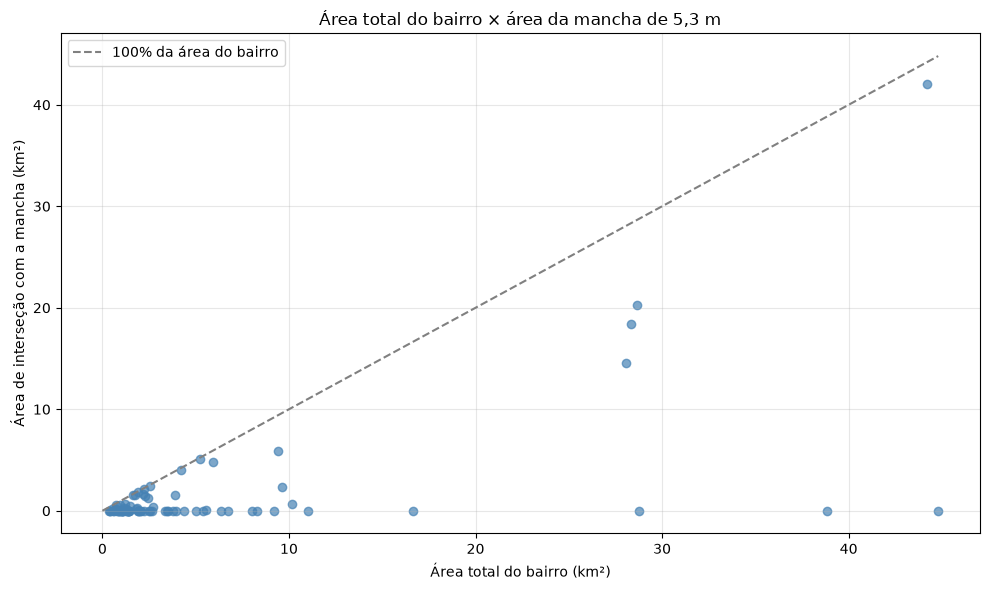

Correlação de Pearson: 0.6305


In [38]:

import matplotlib.pyplot as plt
from pathlib import Path

Path("graficos").mkdir(exist_ok=True)

plt.figure(figsize=(10, 6))

plt.scatter(
    percentual_530["area_bairro_km2"],
    percentual_530["area_mancha_km2"],
    alpha=0.7,
    color="steelblue"
)

# Linha de referência: 100% da área do bairro
limite = percentual_530["area_bairro_km2"].max()

plt.plot(
    [0, limite],
    [0, limite],
    linestyle="--",
    color="gray",
    label="100% da área do bairro"
)

plt.title(
    "Área total do bairro × área da mancha de 5,3 m"
)

plt.xlabel("Área total do bairro (km²)")
plt.ylabel("Área de interseção com a mancha (km²)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "graficos/ufrgs_area_bairro_vs_mancha_530cm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Correlação entre as duas variáveis
correlacao = percentual_530[
    ["area_bairro_km2", "area_mancha_km2"]
].corr().iloc[0, 1]

print("Correlação de Pearson:", round(correlacao, 4))


### Gráfico — Relação entre a área total dos bairros e a área da mancha de 5,3 m

O diagrama de dispersão apresenta a relação entre a área territorial dos 83 bairros de Porto Alegre e a área de interseção com a mancha associada ao nível de 5,3 metros.

Foi identificada uma correlação de Pearson de 0,6305, indicando uma associação linear positiva moderada entre as variáveis. Entretanto, observa-se que bairros com extensões territoriais semelhantes podem apresentar áreas de interseção bastante diferentes.

A linha tracejada representa a situação hipotética em que 100% da área de um bairro estaria coberta pela mancha. Os pontos mais próximos dessa linha apresentam maior cobertura proporcional, enquanto os pontos próximos ao eixo horizontal representam bairros com baixa ou nenhuma interseção.

Os resultados demonstram que a extensão territorial, isoladamente, não é suficiente para caracterizar a cobertura da mancha. Por isso, a análise deve considerar tanto as áreas absolutas quanto os percentuais de cobertura por bairro.

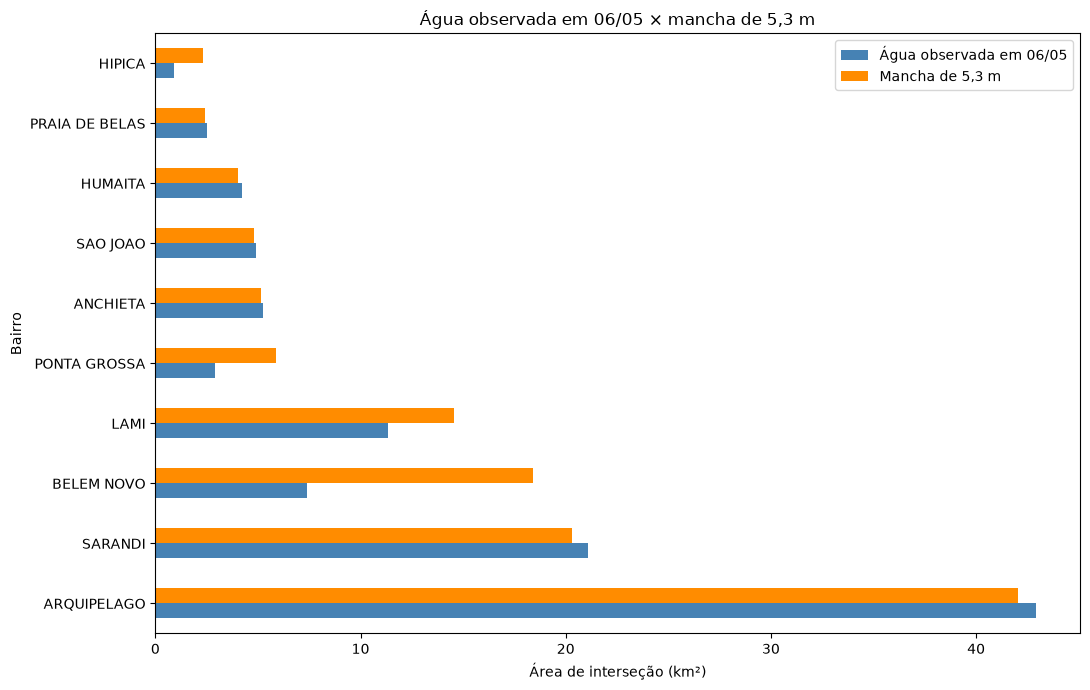

In [39]:

import pandas as pd
import matplotlib.pyplot as plt

# Padronizar os nomes das colunas
comparacao_ufrgs = area_por_bairro.rename(
    columns={
        "area_agua_km2": "agua_06_km2"
    }
).merge(
    area_por_bairro_530.rename(
        columns={
            "area_mancha_km2": "mancha_530_km2"
        }
    ),
    on="bairro",
    how="outer"
)

# Preencher bairros sem interseção com zero
comparacao_ufrgs = comparacao_ufrgs.fillna(0)

# Selecionar os 10 bairros com maior área
# na mancha de 5,3 m
top10_comparacao = comparacao_ufrgs.nlargest(
    10,
    "mancha_530_km2"
)

# Organizar o gráfico
grafico = top10_comparacao.set_index("bairro")[
    ["agua_06_km2", "mancha_530_km2"]
]

grafico.plot(
    kind="barh",
    figsize=(11, 7),
    color=["steelblue", "darkorange"]
)

plt.title(
    "Água observada em 06/05 × mancha de 5,3 m"
)

plt.xlabel("Área de interseção (km²)")
plt.ylabel("Bairro")

plt.legend([
    "Água observada em 06/05",
    "Mancha de 5,3 m"
])

plt.tight_layout()
plt.show()


### Gráfico — Comparação entre a água observada em 06/05/2024 e a mancha de 5,3 m

O gráfico compara as áreas de interseção por bairro entre duas camadas geográficas da UFRGS: a água observada em 6 de maio de 2024 e a mancha associada ao nível de 5,3 metros.

Observa-se que Arquipélago e Sarandi apresentam áreas relativamente semelhantes nas duas camadas, com valores ligeiramente maiores na observação de 06/05. Em contrapartida, Belém Novo, Lami e Ponta Grossa apresentam áreas superiores na mancha de 5,3 m, destacando-se Belém Novo pela diferença entre os resultados.

Essas variações evidenciam diferenças na distribuição espacial das geometrias analisadas. Entretanto, não devem ser interpretadas diretamente como crescimento ou redução da inundação, pois as camadas podem apresentar diferenças de metodologia, cobertura e representação do fenômeno.

A comparação contribui para avaliar a correspondência espacial entre as fontes e identificar bairros que merecem investigação complementar.

In [40]:

# Trabalhar com as duas geometrias em EPSG:31982

agua_06_metros = gdf_poa.to_crs(epsg=31982)
mancha_530_metros = camada_530.to_crs(epsg=31982)

# Unir as geometrias de cada camada
geometria_agua_06 = agua_06_metros.geometry.union_all()
geometria_mancha_530 = mancha_530_metros.geometry.union_all()

# Recortar ambas ao mesmo limite territorial
limite_metros = bairros_poa.to_crs(
    epsg=31982
).geometry.union_all()

geometria_agua_06 = geometria_agua_06.intersection(
    limite_metros
)

geometria_mancha_530 = geometria_mancha_530.intersection(
    limite_metros
)

# Calcular a interseção espacial entre as duas
area_comum = (
    geometria_agua_06.intersection(
        geometria_mancha_530
    ).area / 1_000_000
)

# Calcular a área da união das duas
area_uniao = (
    geometria_agua_06.union(
        geometria_mancha_530
    ).area / 1_000_000
)

# Índice de similaridade espacial (IoU)
iou = (
    area_comum / area_uniao
    if area_uniao > 0 else 0
)

print("Área comum:", round(area_comum, 2), "km²")
print("Área da união:", round(area_uniao, 2), "km²")
print("Similaridade espacial (IoU):", round(iou, 4))
print("Similaridade percentual:", round(iou * 100, 2), "%")


Área comum: 114.94 km²
Área da união: 142.59 km²
Similaridade espacial (IoU): 0.8061
Similaridade percentual: 80.61 %


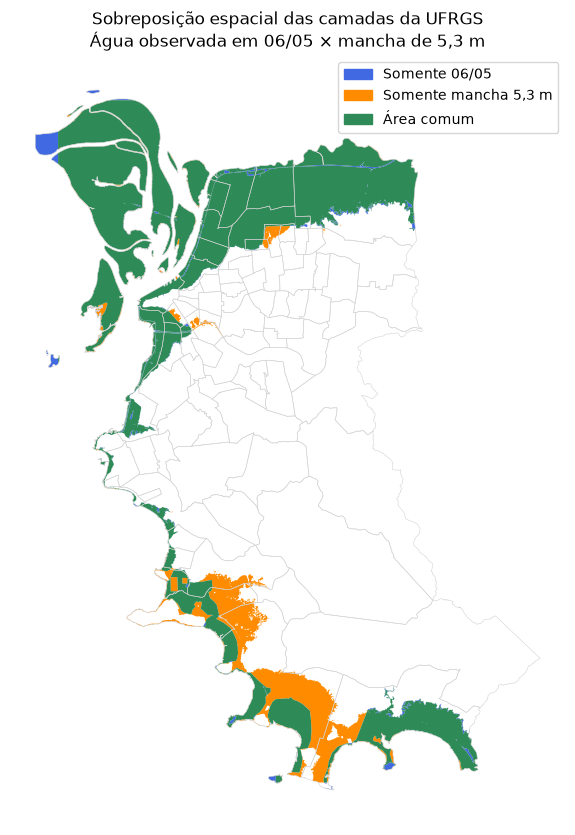

In [41]:

import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path

# Separar as regiões espaciais
area_comum_geom = geometria_agua_06.intersection(
    geometria_mancha_530
)

somente_agua_06 = geometria_agua_06.difference(
    geometria_mancha_530
)

somente_mancha_530 = geometria_mancha_530.difference(
    geometria_agua_06
)

# Criar o mapa
fig, ax = plt.subplots(figsize=(10, 10))

bairros_poa.to_crs(epsg=31982).boundary.plot(
    ax=ax,
    color="lightgray",
    linewidth=0.4
)

# Áreas exclusivas da observação de 06/05
gpd.GeoSeries(
    [somente_agua_06], crs="EPSG:31982"
).plot(
    ax=ax,
    color="royalblue",
    label="Somente 06/05"
)

# Áreas exclusivas da mancha de 5,3 m
gpd.GeoSeries(
    [somente_mancha_530], crs="EPSG:31982"
).plot(
    ax=ax,
    color="darkorange",
    label="Somente mancha 5,3 m"
)

# Área comum
gpd.GeoSeries(
    [area_comum_geom], crs="EPSG:31982"
).plot(
    ax=ax,
    color="seagreen",
    label="Área comum"
)

from matplotlib.patches import Patch

ax.legend(handles=[
    Patch(color="royalblue", label="Somente 06/05"),
    Patch(color="darkorange", label="Somente mancha 5,3 m"),
    Patch(color="seagreen", label="Área comum")
])

ax.set_title(
    "Sobreposição espacial das camadas da UFRGS\n"
    "Água observada em 06/05 × mancha de 5,3 m"
)

ax.set_axis_off()

Path("graficos").mkdir(exist_ok=True)

plt.savefig(
    "graficos/ufrgs_sobreposicao_espacial.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Gráfico — Sobreposição espacial entre a água observada em 06/05/2024 e a mancha de 5,3 m

O mapa apresenta a comparação espacial entre duas camadas geográficas da UFRGS, considerando os limites dos bairros de Porto Alegre. As áreas verdes representam a interseção entre as camadas, enquanto as regiões azuis correspondem exclusivamente à água observada em 06/05/2024 e as regiões laranjas à mancha associada ao nível de 5,3 metros.

Observa-se uma predominância das áreas de sobreposição, especialmente nas regiões norte e noroeste do município. As diferenças mais expressivas aparecem em áreas ao sul, onde a mancha de 5,3 metros apresenta maior extensão em determinados trechos.

O índice Intersection over Union (IoU) calculado foi de 80,61%, indicando elevada coincidência espacial entre as geometrias. Entretanto, esse resultado não representa a precisão de uma camada em relação à outra, pois ambas podem apresentar diferenças de metodologia e finalidade.

A análise contribui para identificar regiões de concordância e divergência entre as representações espaciais, fornecendo informações relevantes para a interpretação das enchentes e para o desenvolvimento das visualizações do sistema.

In [42]:
# Integração com o INCT
import json

with open(
    "data_alterado.json",
    "r",
    encoding="utf-8"
) as arquivo_json:
    dados_inct = json.load(arquivo_json)

print("Tipo de estrutura:", type(dados_inct))

print("\nPrimeiras chaves:")
print(list(dados_inct.keys())[:10])

primeira_chave = next(iter(dados_inct))

print("\nExemplo de conteúdo:")
print(
    json.dumps(
        {primeira_chave: dados_inct[primeira_chave]},
        indent=2,
        ensure_ascii=False
    )[:2000]
)


Tipo de estrutura: <class 'dict'>

Primeiras chaves:
['3_0m', '3_1m', '3_2m', '3_3m', '3_4m', '3_5m', '3_6m', '3_7m', '3_8m', '3_9m']

Exemplo de conteúdo:
{
  "3_0m": {
    "Aberta dos Morros": {
      "affected_buildings": 0,
      "total_buildings": 4696,
      "percentage": 0,
      "population": 9854,
      "affected_population": 0
    },
    "Agronomia": {
      "affected_buildings": 0,
      "total_buildings": 1771,
      "percentage": 0,
      "population": 2677,
      "affected_population": 0
    },
    "Anchieta": {
      "affected_buildings": 28,
      "total_buildings": 589,
      "percentage": 5,
      "population": 791,
      "affected_population": 40
    },
    "Arquipélago": {
      "affected_buildings": 4685,
      "total_buildings": 4688,
      "percentage": 100,
      "population": 6411,
      "affected_population": 6411
    },
    "Auxiliadora": {
      "affected_buildings": 0,
      "total_buildings": 1995,
      "percentage": 0,
      "population": 8909,
      "af

In [43]:
#Extrair os dados do INCT para 5,3 m
import pandas as pd

# Selecionar o cenário de 5,3 metros
nivel_530 = dados_inct["5_3m"]

# Converter os bairros em linhas de uma tabela
inct_530 = pd.DataFrame.from_dict(
    nivel_530,
    orient="index"
).reset_index()

inct_530 = inct_530.rename(
    columns={
        "index": "bairro",
        "percentage": "percentual_edificacoes_afetadas"
    }
)

print("Quantidade de bairros no INCT:", len(inct_530))

print("\nColunas disponíveis:")
print(inct_530.columns.tolist())

display(inct_530.head())


Quantidade de bairros no INCT: 94

Colunas disponíveis:
['bairro', 'affected_buildings', 'total_buildings', 'percentual_edificacoes_afetadas', 'population', 'affected_population']


,bairro,affected_buildings,total_buildings,percentual_edificacoes_afetadas,population,affected_population
0,Aberta dos Morros,252,4696,5,9854,592
1,Agronomia,0,1771,0,2677,0
2,Anchieta,589,589,100,791,791
3,Arquipélago,4688,4688,100,6411,6411
4,Auxiliadora,0,1995,0,8909,0


In [44]:
#Padronizar os nomes dos bairros
import unicodedata

def normalizar_bairro(nome):
    nome = str(nome).strip().upper()

    nome = "".join(
        caractere
        for caractere in unicodedata.normalize("NFD", nome)
        if unicodedata.category(caractere) != "Mn"
    )

    return " ".join(nome.split())

# Criar chaves padronizadas
inct_530["bairro_chave"] = (
    inct_530["bairro"].apply(normalizar_bairro)
)

percentual_530["bairro_chave"] = (
    percentual_530["bairro"].apply(normalizar_bairro)
)

print("Exemplos de bairros normalizados:")
display(
    inct_530[["bairro", "bairro_chave"]].head(10)
)


Exemplos de bairros normalizados:


,bairro,bairro_chave
0,Aberta dos Morros,ABERTA DOS MORROS
1,Agronomia,AGRONOMIA
2,Anchieta,ANCHIETA
3,Arquipélago,ARQUIPELAGO
4,Auxiliadora,AUXILIADORA
5,Azenha,AZENHA
6,Bela Vista,BELA VISTA
7,Belém Novo,BELEM NOVO
8,Belém Velho,BELEM VELHO
9,Boa Vista,BOA VISTA


In [45]:
#Integrar os dados das duas bases

# Integrar UFRGS e INCT
comparacao_inct_ufrgs = percentual_530.merge(
    inct_530,
    on="bairro_chave",
    how="left",
    suffixes=("_ufrgs", "_inct"),
    indicator=True
)

print("Situação da integração:")
print(comparacao_inct_ufrgs["_merge"].value_counts())

# Identificar bairros sem correspondência
print("\nBairros da UFRGS sem correspondência no INCT:")

display(
    comparacao_inct_ufrgs.loc[
        comparacao_inct_ufrgs["_merge"] == "left_only",
        ["bairro_ufrgs"]
    ]
)

# Visualizar a tabela integrada
display(
    comparacao_inct_ufrgs[
        [
            "bairro_ufrgs",
            "percentual_cobertura",
            "percentual_edificacoes_afetadas",
            "affected_buildings",
            "affected_population"
        ]
    ].head(10)
)


Situação da integração:
_merge
both          79
left_only      4
right_only     0
Name: count, dtype: int64

Bairros da UFRGS sem correspondência no INCT:


,bairro_ufrgs
38,CEL APARICIO BORGES
53,MONTSERRAT
66,PASSO DAREIA
68,SAO JOSE


,bairro_ufrgs,percentual_cobertura,percentual_edificacoes_afetadas,affected_buildings,affected_population
0,FARRAPOS,98.103187,100.0,5510.0,17591.0
1,NAVEGANTES,97.923265,100.0,3232.0,3315.0
2,ANCHIETA,97.869796,100.0,589.0,791.0
3,SAO GERALDO,97.138545,91.0,3144.0,6323.0
4,HUMAITA,95.659621,100.0,2087.0,12744.0
5,ARQUIPELAGO,95.120969,100.0,4688.0,6411.0
6,PRAIA DE BELAS,93.555503,100.0,290.0,1522.0
7,SERRARIA,87.107357,87.0,2560.0,3859.0
8,SAO JOAO,81.234547,35.0,1118.0,3718.0
9,SANTA MARIA GORETTI,80.351521,40.0,709.0,1214.0


In [46]:

# Quantidade de bairros correspondentes
print("Resultado da integração:")
print(comparacao_inct_ufrgs["_merge"].value_counts())

# Bairros da UFRGS sem correspondência
sem_correspondencia = comparacao_inct_ufrgs[
    comparacao_inct_ufrgs["_merge"] == "left_only"
]

print("\nBairros sem correspondência:")
display(sem_correspondencia[["bairro_ufrgs"]])

# Verificar duplicações das chaves normalizadas
print("\nChaves duplicadas na UFRGS:")
print(percentual_530["bairro_chave"].duplicated().sum())

print("\nChaves duplicadas no INCT:")
print(inct_530["bairro_chave"].duplicated().sum())


Resultado da integração:
_merge
both          79
left_only      4
right_only     0
Name: count, dtype: int64

Bairros sem correspondência:


,bairro_ufrgs
38,CEL APARICIO BORGES
53,MONTSERRAT
66,PASSO DAREIA
68,SAO JOSE



Chaves duplicadas na UFRGS:
0

Chaves duplicadas no INCT:
0


In [47]:

# Recalcular o percentual a partir das contagens
inct_530["percentual_calculado"] = (
    inct_530["affected_buildings"]
    / inct_530["total_buildings"].replace(0, float("nan"))
) * 100

# Diferença entre o percentual informado e o calculado
inct_530["diferenca_percentual"] = (
    inct_530["percentual_edificacoes_afetadas"]
    - inct_530["percentual_calculado"]
).abs()

print("Maior diferença percentual:")
print(inct_530["diferenca_percentual"].max())

print("\nBairros com diferença superior a 1 ponto percentual:")
display(
    inct_530.loc[
        inct_530["diferenca_percentual"] > 1,
        [
            "bairro",
            "percentual_edificacoes_afetadas",
            "percentual_calculado",
            "diferenca_percentual"
        ]
    ]
)


Maior diferença percentual:
0.4947735191637719

Bairros com diferença superior a 1 ponto percentual:


,bairro,percentual_edificacoes_afetadas,percentual_calculado,diferenca_percentual


In [48]:

import difflib

nao_encontrados = comparacao_inct_ufrgs.loc[
    comparacao_inct_ufrgs["_merge"] == "left_only",
    "bairro_ufrgs"
]

for bairro in nao_encontrados:
    semelhantes = difflib.get_close_matches(
        normalizar_bairro(bairro),
        inct_530["bairro_chave"].tolist(),
        n=5,
        cutoff=0.4
    )

    print(f"\nBairro UFRGS: {bairro}")
    print("Possíveis correspondências:", semelhantes)



Bairro UFRGS: CEL APARICIO BORGES
Possíveis correspondências: ['CORONEL APARICIO BORGES', 'JARDIM FLORESTA', 'PRAIA DE BELAS', 'SANTA MARIA GORETTI', 'RIO BRANCO']

Bairro UFRGS: MONTSERRAT
Possíveis correspondências: ["MONT'SERRAT", 'SERRARIA', 'MORRO SANTANA', 'SANTA TEREZA', 'SAO SEBASTIAO']

Bairro UFRGS: PASSO DAREIA
Possíveis correspondências: ["PASSO D'AREIA", 'PASSO DAS PEDRAS', 'SAO CAETANO', 'SERRARIA', 'SAO SEBASTIAO']

Bairro UFRGS: SAO JOSE
Possíveis correspondências: ['VILA SAO JOSE', 'SAO JOAO', 'SAO SEBASTIAO', 'SAO GERALDO', 'SAO CAETANO']


In [49]:

# Criar cópia para preservar os dados originais
ufrgs_integracao = percentual_530.copy()

# Dicionário de equivalências de nomenclatura
equivalencias = {
    "CEL APARICIO BORGES": "CORONEL APARICIO BORGES",
    "MONTSERRAT": "MONT'SERRAT",
    "PASSO DAREIA": "PASSO D'AREIA"
}

# Aplicar correções apenas na chave de integração
ufrgs_integracao["bairro_chave"] = (
    ufrgs_integracao["bairro_chave"]
    .replace(equivalencias)
)

# Refazer a integração
comparacao_corrigida = ufrgs_integracao.merge(
    inct_530,
    on="bairro_chave",
    how="left",
    suffixes=("_ufrgs", "_inct"),
    indicator=True,
    validate="one_to_one"
)

print("Resultado da integração corrigida:")
print(comparacao_corrigida["_merge"].value_counts())

print("\nBairros ainda sem correspondência:")
display(
    comparacao_corrigida.loc[
        comparacao_corrigida["_merge"] == "left_only",
        ["bairro_ufrgs"]
    ]
)


Resultado da integração corrigida:
_merge
both          82
left_only      1
right_only     0
Name: count, dtype: int64

Bairros ainda sem correspondência:


,bairro_ufrgs
68,SAO JOSE


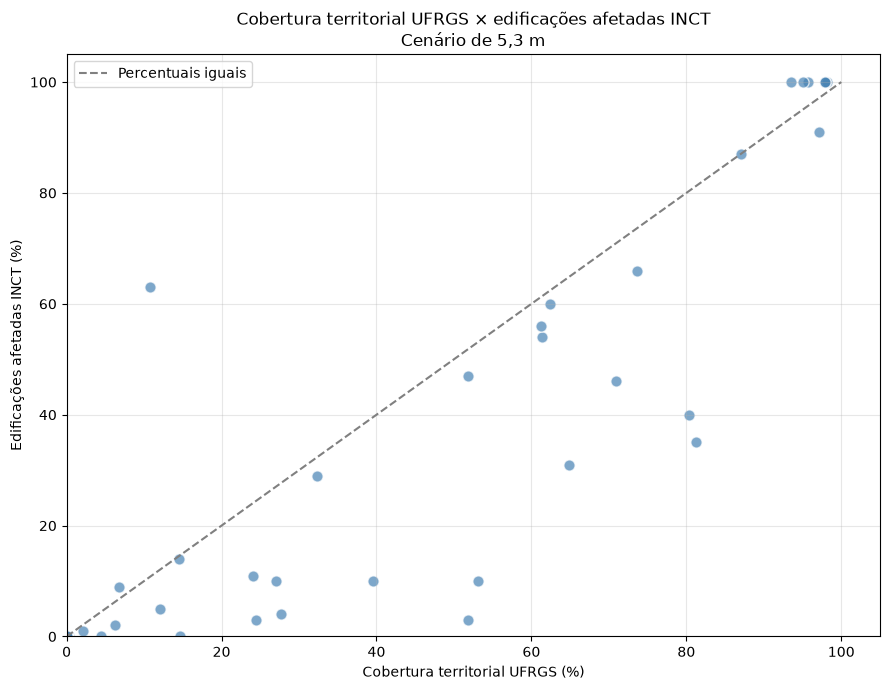

Correlação de Pearson: 0.9187
Bairros comparados: 82


In [50]:

import matplotlib.pyplot as plt
from pathlib import Path

# Selecionar apenas bairros com correspondência
dados_comparacao = comparacao_corrigida.loc[
    comparacao_corrigida["_merge"] == "both"
].copy()

# Selecionar as duas variáveis
x = dados_comparacao["percentual_cobertura"]
y = dados_comparacao["percentual_edificacoes_afetadas"]

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    x,
    y,
    color="steelblue",
    alpha=0.7,
    edgecolors="white",
    s=65
)

# Linha de referência: percentuais iguais
ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    label="Percentuais iguais"
)

ax.set_title(
    "Cobertura territorial UFRGS × edificações afetadas INCT\n"
    "Cenário de 5,3 m"
)

ax.set_xlabel("Cobertura territorial UFRGS (%)")
ax.set_ylabel("Edificações afetadas INCT (%)")

ax.set_xlim(0, 105)
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

Path("graficos").mkdir(exist_ok=True)

plt.savefig(
    "graficos/ufrgs_inct_comparacao_530cm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Calcular a correlação
correlacao = x.corr(y)

print(
    "Correlação de Pearson:",
    round(correlacao, 4)
)

print(
    "Bairros comparados:",
    len(dados_comparacao)
)


### Gráfico — Relação entre cobertura territorial da UFRGS e edificações afetadas do INCT

O diagrama de dispersão apresenta a relação entre o percentual de cobertura territorial pela mancha de 5,3 metros da UFRGS e o percentual de edificações afetadas na simulação do INCT, considerando 82 bairros com correspondência entre as bases.

Foi identificada uma correlação de Pearson de 0,9187, indicando uma associação linear positiva muito forte entre os indicadores. De modo geral, bairros com maiores percentuais de cobertura territorial também apresentam maiores percentuais de edificações afetadas.

Apesar dessa associação, o gráfico evidencia diferenças relevantes em determinados bairros, demonstrando que a cobertura territorial não corresponde necessariamente à proporção de edificações afetadas.

Os resultados contribuem para relacionar informações geográficas e indicadores de impacto, mas não comprovam a precisão da simulação. A comparação deve considerar as diferenças metodológicas e a necessidade de verificar a equivalência das delimitações territoriais utilizadas pelas fontes.

In [51]:

# Calcular a diferença entre os dois indicadores
dados_comparacao["diferenca_pp"] = (
    dados_comparacao["percentual_edificacoes_afetadas"]
    - dados_comparacao["percentual_cobertura"]
)

# Calcular a diferença absoluta
dados_comparacao["diferenca_absoluta_pp"] = (
    dados_comparacao["diferenca_pp"].abs()
)

# Identificar os dez bairros com maiores diferenças
maiores_divergencias = (
    dados_comparacao
    .sort_values(
        "diferenca_absoluta_pp",
        ascending=False
    )
    .head(10)
)

display(
    maiores_divergencias[
        [
            "bairro_ufrgs",
            "percentual_cobertura",
            "percentual_edificacoes_afetadas",
            "diferenca_pp"
        ]
    ]
)

# Correlação apenas entre bairros com
# valores positivos nos dois indicadores
ambos_positivos = dados_comparacao[
    (dados_comparacao["percentual_cobertura"] > 0)
    & (dados_comparacao["percentual_edificacoes_afetadas"] > 0)
]

print(
    "\nBairros com ambos os indicadores positivos:",
    len(ambos_positivos)
)

print(
    "Correlação nesses bairros:",
    round(
        ambos_positivos["percentual_cobertura"].corr(
            ambos_positivos["percentual_edificacoes_afetadas"]
        ),
        4
    )
)


,bairro_ufrgs,percentual_cobertura,percentual_edificacoes_afetadas,diferenca_pp
28,ESPIRITO SANTO,10.816114,63.0,52.183886
18,JARDIM SAO PEDRO,51.777682,3.0,-48.777682
8,SAO JOAO,81.234547,35.0,-46.234547
16,CENTRO HISTORICO,53.051458,10.0,-43.051458
9,SANTA MARIA GORETTI,80.351521,40.0,-40.351521
12,BELEM NOVO,64.888688,31.0,-33.888688
19,CRISTAL,39.519836,10.0,-29.519836
11,SARANDI,70.907354,46.0,-24.907354
21,JARDIM FLORESTA,27.715825,4.0,-23.715825
23,HIPICA,24.388068,3.0,-21.388068



Bairros com ambos os indicadores positivos: 31
Correlação nesses bairros: 0.8438


In [52]:

from pathlib import Path

Path("dados/tratados").mkdir(
    parents=True,
    exist_ok=True
)

# Selecionar as colunas relevantes
dados_integrados = dados_comparacao[
    [
        "bairro_ufrgs",
        "area_bairro_km2",
        "area_mancha_km2",
        "percentual_cobertura",
        "total_buildings",
        "affected_buildings",
        "percentual_edificacoes_afetadas",
        "population",
        "affected_population",
        "diferenca_pp"
    ]
].copy()

dados_integrados.to_csv(
    "dados/tratados/ufrgs_inct_integrados_530cm.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo integrado salvo com sucesso!")
print("Total de bairros:", len(dados_integrados))


Arquivo integrado salvo com sucesso!
Total de bairros: 82


In [53]:

import numpy as np

# Trabalhar apenas com os 82 bairros correspondentes
dados_populacao = dados_comparacao.copy()

# Calcular o percentual da população afetada
dados_populacao["percentual_populacao_afetada"] = (
    dados_populacao["affected_population"]
    / dados_populacao["population"].replace(0, np.nan)
) * 100

# Verificar consistência dos resultados
print("Bairros analisados:", len(dados_populacao))

print("Populações totais iguais a zero:",
      (dados_populacao["population"] == 0).sum())

print("Percentuais acima de 100%:",
      (dados_populacao["percentual_populacao_afetada"] > 100).sum())

print("Percentuais ausentes:",
      dados_populacao["percentual_populacao_afetada"].isna().sum())

display(
    dados_populacao[
        [
            "bairro_ufrgs",
            "population",
            "affected_population",
            "percentual_populacao_afetada"
        ]
    ].head(10)
)


Bairros analisados: 82
Populações totais iguais a zero: 0
Percentuais acima de 100%: 0
Percentuais ausentes: 0


,bairro_ufrgs,population,affected_population,percentual_populacao_afetada
0,FARRAPOS,17591.0,17591.0,100.000000
1,NAVEGANTES,3315.0,3315.0,100.000000
2,ANCHIETA,791.0,791.0,100.000000
3,SAO GERALDO,6948.0,6323.0,91.004606
4,HUMAITA,12744.0,12744.0,100.000000
5,ARQUIPELAGO,6411.0,6411.0,100.000000
6,PRAIA DE BELAS,1522.0,1522.0,100.000000
7,SERRARIA,4385.0,3859.0,88.004561
8,SAO JOAO,10621.0,3718.0,35.006120
9,SANTA MARIA GORETTI,3035.0,1214.0,40.000000


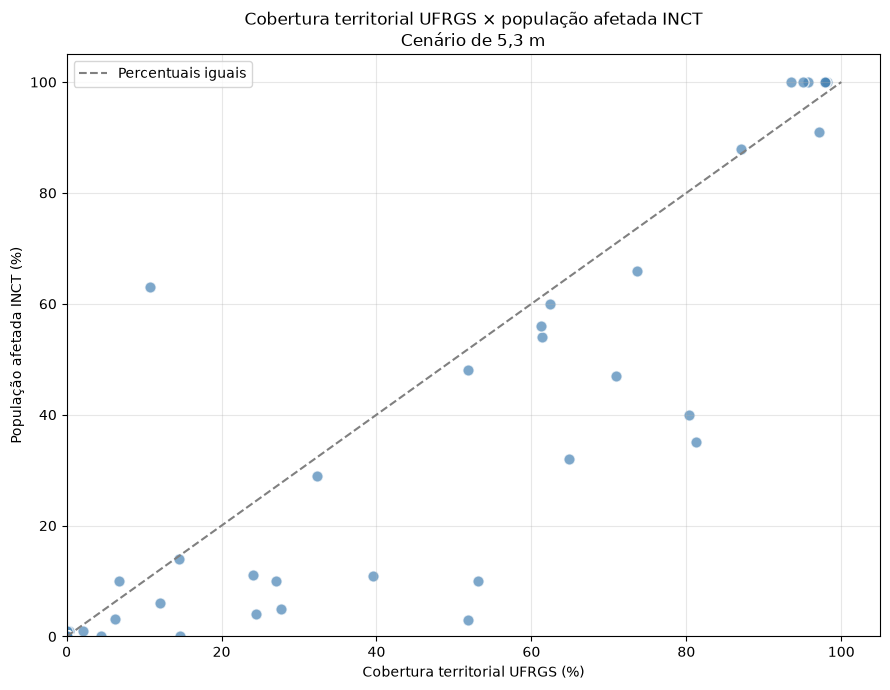

Correlação de Pearson: 0.9198
Bairros no gráfico: 82


In [54]:

import matplotlib.pyplot as plt
from pathlib import Path

# Remover apenas registros sem percentual calculável
dados_grafico_pop = dados_populacao.dropna(
    subset=[
        "percentual_cobertura",
        "percentual_populacao_afetada"
    ]
).copy()

x = dados_grafico_pop["percentual_cobertura"]
y = dados_grafico_pop["percentual_populacao_afetada"]

fig, ax = plt.subplots(figsize=(9, 7))

ax.scatter(
    x,
    y,
    color="steelblue",
    alpha=0.7,
    edgecolors="white",
    s=65
)

# Linha de referência
ax.plot(
    [0, 100],
    [0, 100],
    linestyle="--",
    color="gray",
    label="Percentuais iguais"
)

ax.set_title(
    "Cobertura territorial UFRGS × população afetada INCT\n"
    "Cenário de 5,3 m"
)

ax.set_xlabel("Cobertura territorial UFRGS (%)")
ax.set_ylabel("População afetada INCT (%)")

ax.set_xlim(0, 105)
ax.set_ylim(0, 105)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

Path("graficos").mkdir(exist_ok=True)

plt.savefig(
    "graficos/ufrgs_inct_populacao_530cm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Correlação de Pearson:",
    round(x.corr(y), 4)
)

print("Bairros no gráfico:", len(dados_grafico_pop))


### Gráfico — Relação entre cobertura territorial da UFRGS e população afetada do INCT

O diagrama de dispersão apresenta a relação entre o percentual de cobertura territorial pela mancha de 5,3 metros da UFRGS e o percentual de população afetada estimado pelo INCT, considerando 82 bairros com correspondência entre as bases.

Foi identificada uma correlação de Pearson de 0,9198, indicando uma associação linear positiva muito forte. De maneira geral, bairros com maiores percentuais de cobertura territorial também apresentam maiores proporções de população afetada.

O resultado é semelhante à correlação observada entre cobertura territorial e edificações afetadas (0,9187), sugerindo comportamentos próximos dos dois indicadores de impacto em relação à distribuição territorial da mancha.

Entretanto, existem diferenças expressivas em determinados bairros, evidenciando que a proporção territorial coberta pela mancha não corresponde necessariamente à proporção de moradores afetados.

A análise contribui para relacionar informações geográficas e sociais no cenário de 5,3 metros. Ressalta-se que a correlação não comprova causalidade nem valida a precisão das estimativas do INCT, sendo necessário considerar as diferenças metodológicas e territoriais entre as fontes.

In [55]:

# Comparar os dois indicadores do INCT
dados_populacao["diferenca_pop_edificacoes"] = (
    dados_populacao["percentual_populacao_afetada"]
    - dados_populacao["percentual_edificacoes_afetadas"]
).abs()

print("Correlação população × edificações:")
print(
    round(
        dados_populacao["percentual_populacao_afetada"].corr(
            dados_populacao["percentual_edificacoes_afetadas"]
        ),
        4
    )
)

print("\nMaior diferença em pontos percentuais:")
print(
    round(
        dados_populacao["diferenca_pop_edificacoes"].max(),
        4
    )
)

print("\nBairros com diferença acima de 5 p.p.:")
print(
    (dados_populacao["diferenca_pop_edificacoes"] > 5).sum()
)

display(
    dados_populacao.nlargest(
        10, "diferenca_pop_edificacoes"
    )[
        [
            "bairro_ufrgs",
            "percentual_edificacoes_afetadas",
            "percentual_populacao_afetada",
            "diferenca_pop_edificacoes"
        ]
    ]
)


Correlação população × edificações:
0.9999

Maior diferença em pontos percentuais:
1.096

Bairros com diferença acima de 5 p.p.:
0


,bairro_ufrgs,percentual_edificacoes_afetadas,percentual_populacao_afetada,diferenca_pop_edificacoes
30,VILA CONCEICAO,2.0,3.095975,1.095975
21,JARDIM FLORESTA,4.0,5.026930,1.026930
33,CHAPEU DO SOL,0.0,1.009555,1.009555
12,BELEM NOVO,31.0,32.006903,1.006903
27,TRISTEZA,5.0,6.005465,1.005465
29,IPANEMA,9.0,10.005223,1.005223
7,SERRARIA,87.0,88.004561,1.004561
35,LAGEADO,0.0,1.004228,1.004228
19,CRISTAL,10.0,11.001569,1.001569
11,SARANDI,46.0,47.001300,1.001300


In [56]:

import json
import pandas as pd

with open("data.json", encoding="utf-8") as f:
    dados_originais = json.load(f)

with open("data_alterado.json", encoding="utf-8") as f:
    dados_tratados = json.load(f)

def calcular_correlacao_inct(dados, nivel="5_3m"):
    df = pd.DataFrame.from_dict(
        dados[nivel], orient="index"
    )

    edificacoes_pct = (
        df["affected_buildings"]
        / df["total_buildings"].replace(0, float("nan"))
    ) * 100

    populacao_pct = (
        df["affected_population"]
        / df["population"].replace(0, float("nan"))
    ) * 100

    return edificacoes_pct.corr(populacao_pct)

print(
    "Correlação no JSON original:",
    round(calcular_correlacao_inct(dados_originais), 4)
)

print(
    "Correlação no JSON tratado:",
    round(calcular_correlacao_inct(dados_tratados), 4)
)


Correlação no JSON original: 1.0
Correlação no JSON tratado: 1.0
